# **03 · The Bread Basket: análisis exploratorio y preprocesamiento**

Este notebook prepara el set de prueba final: las ventas de una cafetería y panadería de Edimburgo. Como es la prueba, se le aplican **las mismas reglas acordadas para los datasets de entrenamiento**, sin ajustarlas a lo que se vea aquí; elegir reglas mirando la prueba inflaría las métricas finales. El análisis sirve para describir y verificar, y las únicas decisiones nuevas son las que este dataset obliga a tomar.

## **0. Contexto y fuente**

- **Origen:** transacciones de *The Bread Basket*, una cafetería y panadería en Edimburgo, Escocia, de octubre de 2016 a abril de 2017.
- **Publicación:** [OpenML, dataset 43422](https://www.openml.org/d/43422), con licencia CC0 (dominio público).
- **Por qué se usa:** es un negocio pequeño que vende café, pasteles, pastries y panes en volúmenes de pocas unidades al día, lo más parecido a un negocio como Sakura entre los datos públicos disponibles.
- **Papel en el proyecto:** prueba final. El modelo no lo ve durante el entrenamiento, y al final se carga en Restocker como el negocio de la demostración.
- **Limitaciones conocidas:** solo cubre unas 23 semanas y no trae columna de cantidad.

## **1. Descarga reproducible**

Los datos se descargan de OpenML en formato ARFF, el formato de texto que usa esa plataforma. Se guardan en `data/raw/bread_basket/`, que también se versiona en el repositorio; si ya existen, no se vuelven a descargar.

In [1]:
import csv
import io
from pathlib import Path

import pandas as pd
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "bread_basket"
RAW.mkdir(parents=True, exist_ok=True)

# Archivo del dataset 43422 (versión 1) en OpenML
URL = "https://openml.org/data/v1/download/22102247/The-Bread-Basket.arff"

path = RAW / "the_bread_basket.arff"
if not path.exists():
    response = requests.get(URL, timeout=120)
    response.raise_for_status()
    path.write_bytes(response.content)
print(f"{path.name}: {path.stat().st_size / 1024:,.0f} KB")

the_bread_basket.arff: 978 KB


Un archivo ARFF tiene un encabezado que describe las columnas (`@ATTRIBUTE`) y después los datos (`@DATA`) en formato CSV, con comillas simples y barras invertidas para escapar apóstrofes, como en `Valentine\'s card`. Por eso se lee con el módulo `csv` indicando esos caracteres.

In [2]:
text = path.read_text(encoding="utf-8")
columns = [line.split()[1] for line in text.splitlines() if line.upper().startswith("@ATTRIBUTE")]
body = text[text.upper().index("@DATA") + len("@DATA"):].strip()
rows = csv.reader(io.StringIO(body), quotechar="'", escapechar="\\", skipinitialspace=True)

raw = pd.DataFrame(rows, columns=columns)
raw["Transaction"] = raw["Transaction"].astype(int)
raw["date_time"] = pd.to_datetime(raw["date_time"], format="%d-%m-%Y %H:%M")
raw.head()

,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,2016-10-30 09:58:00,morning,weekend
1,2,Scandinavian,2016-10-30 10:05:00,morning,weekend
2,2,Scandinavian,2016-10-30 10:05:00,morning,weekend
3,3,Hot chocolate,2016-10-30 10:07:00,morning,weekend
4,3,Jam,2016-10-30 10:07:00,morning,weekend


## **2. Composición**

Cada fila es **un producto dentro de una compra**, y no hay columna de cantidad: si un cliente compra dos piezas del mismo producto, aparecen dos filas iguales.

- `Transaction`: número de la compra (ticket).
- `Item`: nombre del producto.
- `date_time`: fecha y hora de la compra.
- `period_day`: momento del día (`morning`, `afternoon`, `evening` o `night`).
- `weekday_weekend`: si la compra fue entre semana o en fin de semana.

In [3]:
raw.dtypes

Transaction                 int64
Item                          str
date_time          datetime64[us]
period_day                    str
weekday_weekend               str
dtype: object

In [4]:
raw["date"] = raw["date_time"].dt.normalize()
calendar_days = (raw["date"].max() - raw["date"].min()).days + 1

print(f"Filas: {len(raw):,}")
print(f"Compras: {raw['Transaction'].nunique():,} | Productos: {raw['Item'].nunique()}")
print(f"Rango: {raw['date'].min().date()} a {raw['date'].max().date()} ({calendar_days} días de calendario, {raw['date'].nunique()} con ventas)")

Filas: 20,507
Compras: 9,465 | Productos: 94
Rango: 2016-10-30 a 2017-04-09 (162 días de calendario, 159 con ventas)


## **3. Calidad**

El dataset no tiene valores nulos. Como no hay columna de cantidad, la celda también cuenta cuántas veces un mismo producto aparece repetido dentro de una compra, que es la evidencia de que cada fila representa una unidad.

In [5]:
checks = {
    "Valores nulos": int(raw.isna().sum().sum()),
    "Nombres vacíos": int((raw["Item"].str.strip() == "").sum()),
    "Producto repetido dentro de una compra": int(raw.duplicated(["Transaction", "Item"]).sum()),
}
pd.Series(checks, name="Cantidad").to_frame()

,Cantidad
Valores nulos,0
Nombres vacíos,0
Producto repetido dentro de una compra,1620


In [6]:
repeated = raw[raw.duplicated(["Transaction", "Item"], keep=False)]
repeated.head(6)[["Transaction", "Item", "date_time"]]

,Transaction,Item,date_time
1,2,Scandinavian,2016-10-30 10:05:00
2,2,Scandinavian,2016-10-30 10:05:00
23,11,Bread,2016-10-30 10:27:00
25,11,Bread,2016-10-30 10:27:00
48,21,Coffee,2016-10-30 10:49:00
49,21,Coffee,2016-10-30 10:49:00


Un mismo producto aparece varias veces en una compra porque el cliente se llevó varias unidades. Por eso las ventas diarias se obtienen **contando filas** por producto y día.

## **4. Agregación a ventas diarias**

Se aplican las mismas reglas que en French Bakery:

- Las filas se cuentan por producto y día.
- Se reconstruye el calendario completo. Un día **sin ninguna compra** es un cierre (`is_open = False`).
- Si el local abrió y un producto no aparece, ese producto vendió 0.

In [7]:
daily_sales = raw.groupby(["Item", "date"]).size().rename("sales").reset_index()

calendar = pd.date_range(raw["date"].min(), raw["date"].max(), freq="D")
open_dates = set(raw["date"].unique())
grid = pd.MultiIndex.from_product([sorted(raw["Item"].unique()), calendar], names=["Item", "date"]).to_frame(index=False)

df = grid.merge(daily_sales, on=["Item", "date"], how="left")
df["sales"] = df["sales"].fillna(0).astype(int)
df["is_open"] = df["date"].isin(open_dates)
df["day_of_week"] = df["date"].dt.day_of_week

closed = sorted(set(calendar) - open_dates)
print(f"Filas: {len(df):,} ({df['Item'].nunique()} productos × {len(calendar)} días)")
print("Días cerrados:", [d.strftime("%Y-%m-%d (%a)") for d in closed])

Filas: 15,228 (94 productos × 162 días)
Días cerrados: ['2016-12-25 (Sun)', '2016-12-26 (Mon)', '2017-01-02 (Mon)']


## **5. Selección de productos**

Se aplican las tres reglas de French Bakery:

1. **Excluir lo que no es un producto que se produce:** ajustes de caja, mercancía, tarjetas, eventos, objetos decorativos y bebidas embotelladas que se compran y se revenden (`Coke` y `Mineral water`), igual que `BOISSON 33CL` en French Bakery. `Juice` se conserva porque el dataset no indica si es natural o embotellado; queda como supuesto.
2. **Recortar cada serie a su vida activa**, desde su primera hasta su última venta.
3. **Conservar los productos vendidos en al menos el 50 % de los días abiertos de su vida activa**, con un mínimo de 90 días abiertos.

In [8]:
not_products = [
    "Adjustment",                  # ajuste de caja
    "Gift voucher", "Postcard", "Tshirt", "Nomad bag", "Valentine's card",  # mercancía y tarjetas
    "Afternoon with the baker", "Argentina Night",  # eventos
    "Fairy Doors", "Art Tray", "Basket",  # objetos decorativos
    "Coke", "Mineral water",  # bebidas embotelladas que se revenden
]
missing = [item for item in not_products if item not in set(df["Item"])]
assert not missing, f"Nombres que no existen en el dataset: {missing}"

df = df[~df["Item"].isin(not_products)]
print(f"Excluidos: {len(not_products)} | Productos restantes: {df['Item'].nunique()}")

Excluidos: 13 | Productos restantes: 81


In [9]:
sold = df[df["sales"] > 0]
life = sold.groupby("Item")["date"].agg(first_sale="min", last_sale="max")
df = df.merge(life, on="Item")
df = df[(df["date"] >= df["first_sale"]) & (df["date"] <= df["last_sale"])].drop(columns=["first_sale", "last_sale"])

open_in_life = df[df["is_open"]]
coverage = pd.DataFrame({
    "dias_abiertos": open_in_life.groupby("Item").size(),
    "dias_con_venta": open_in_life[open_in_life["sales"] > 0].groupby("Item").size(),
}).fillna(0)
coverage["cobertura"] = coverage["dias_con_venta"] / coverage["dias_abiertos"]

keep = coverage[(coverage["cobertura"] >= 0.5) & (coverage["dias_abiertos"] >= 90)].index
df = df[df["Item"].isin(keep)]
print(f"Conservados: {len(keep)} productos | Filas: {len(df):,}")
coverage.loc[keep].sort_values("cobertura", ascending=False).round(2)

Conservados: 20 productos | Filas: 3,144


,dias_abiertos,dias_con_venta,cobertura
Item,,,
Bread,159,159,1.00
Coffee,159,158,0.99
Tea,159,158,0.99
Sandwich,158,155,0.98
Pastry,159,149,0.94
Toast,126,117,0.93
Cake,159,146,0.92
Hot chocolate,159,146,0.92
Cookies,159,144,0.91


## **6. Comparación con el entrenamiento**

Como este dataset es la prueba, en lugar de repetir todo el análisis se compara contra los datasets de entrenamiento ya procesados. La pregunta es si el modelo va a enfrentar series parecidas a las que aprendió, en escala, intermitencia y ciclo semanal.

In [10]:
import matplotlib.pyplot as plt

train = pd.concat([
    pd.read_parquet(ROOT / "data" / "processed" / "ddop_bakery.parquet"),
    pd.read_parquet(ROOT / "data" / "processed" / "french_bakery.parquet"),
])
test = df.rename(columns={"Item": "product_id"}).assign(dataset="bread_basket", store_id="bread_basket_1")
both = pd.concat([train, test[train.columns]])
both = both[both["is_open"]]
both["series"] = both["store_id"] + "/" + both["product_id"]

per_series = both.groupby(["dataset", "series"])["sales"].agg(promedio="mean", dias_en_cero=lambda s: (s == 0).mean())
per_series.groupby("dataset").median().round(2).rename(columns={"promedio": "venta promedio (mediana)", "dias_en_cero": "días en cero (mediana)"})

,venta promedio (mediana),días en cero (mediana)
dataset,,
bread_basket,2.57,0.16
ddop,68.64,0.00
french_bakery,3.97,0.12


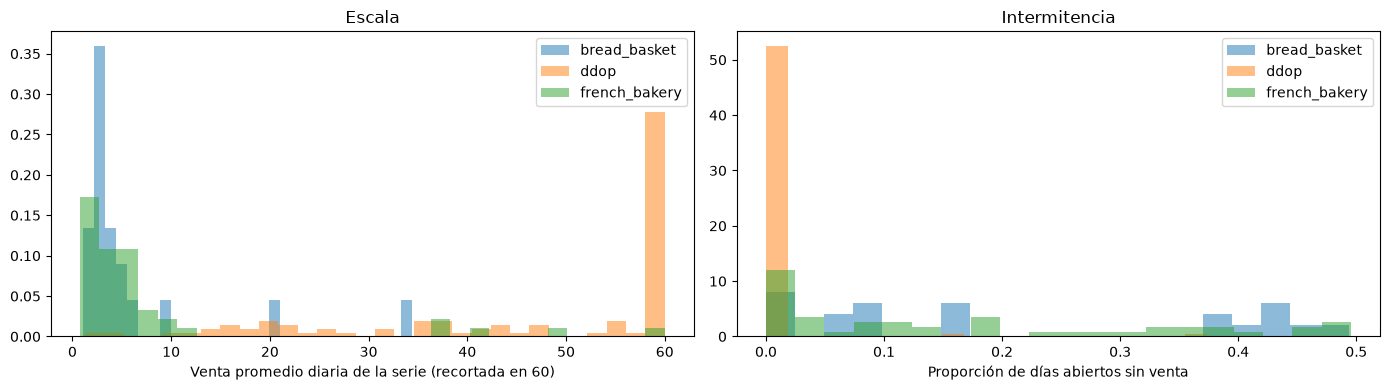

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, group in per_series.groupby("dataset"):
    axes[0].hist(group["promedio"].clip(upper=60), bins=30, alpha=0.5, density=True, label=name)
    axes[1].hist(group["dias_en_cero"], bins=20, alpha=0.5, density=True, label=name)
axes[0].set_xlabel("Venta promedio diaria de la serie (recortada en 60)")
axes[0].set_title("Escala")
axes[1].set_xlabel("Proporción de días abiertos sin venta")
axes[1].set_title("Intermitencia")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [12]:
both["relative"] = both["sales"] / both.groupby("series")["sales"].transform("mean")
both["day_of_week"] = both["date"].dt.day_of_week
day_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

weekly = both.groupby(["dataset", "day_of_week"])["relative"].mean().unstack(0)
weekly.index = day_names
weekly.round(2)

dataset,bread_basket,ddop,french_bakery
Lun,0.88,0.90,0.88
Mar,0.78,0.86,0.85
Mié,0.74,0.88,0.90
Jue,0.89,0.89,0.88
Vie,1.08,0.97,0.96
Sáb,1.60,1.29,1.11
Dom,1.02,1.32,1.38


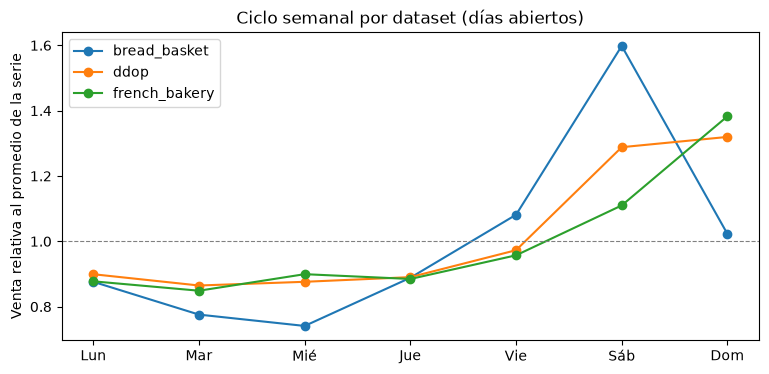

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in weekly.columns:
    ax.plot(day_names, weekly[name], marker="o", label=name)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Ciclo semanal por dataset (días abiertos)")
ax.legend()
plt.show()

**Conclusiones de la sección:**

- **Escala e intermitencia:** The Bread Basket vende 2.6 unidades al día por serie (mediana) y pasa un 16 % de los días abiertos sin venta, muy parecido a French Bakery. Sin French Bakery en el entrenamiento, el modelo no habría visto series de esta escala.
- **Ciclo semanal:** se comparte la idea general (el fin de semana vende más), pero el día pico cambia: aquí es el **sábado** (1.60), mientras que en ddop y French Bakery es el domingo. Si el modelo recibiera el día de la semana como variable, podría aprender que "los domingos se vende más" y fallar aquí; si en cambio lee los días anteriores de la ventana, ve el patrón propio de este negocio. Por eso se entrenará el modelo base con y sin esa variable y se compararán los resultados en este dataset.

## **7. Decisiones de preprocesamiento**

| # | Decisión | Justificación | Sección |
| :- | :- | :- | :- |
| 1 | Las reglas son las mismas que en los datasets de entrenamiento; no se ajustan a este dataset. | Es la prueba: elegir reglas mirando sus datos inflaría las métricas finales. | — |
| 2 | Las ventas diarias se obtienen contando filas por producto y día. | No hay columna de cantidad, y un mismo producto se repite dentro de una compra (1,620 casos), así que cada fila es una unidad. | 3 y 4 |
| 3 | Un día sin ninguna compra es un cierre (`is_open = False`); si el local abrió y un producto no aparece, vendió 0. | Misma regla que en ddop y French Bakery. Los cierres coinciden con feriados británicos. | 4 |
| 4 | Se excluyen ajustes de caja, mercancía, tarjetas, eventos, objetos decorativos y bebidas embotelladas (`Coke`, `Mineral water`). | No son productos que se produzcan; misma regla que en French Bakery. `Juice` se conserva como supuesto. | 5 |
| 5 | Cada producto se recorta a su vida activa y se conservan los vendidos en al menos el 50 % de los días abiertos, con un mínimo de 90. | Misma regla que en French Bakery. | 5 |
| 6 | El modelo base se entrenará con y sin el día de la semana como variable. | El pico de este negocio es el sábado, no el domingo como en el entrenamiento. | 6 |
| 7 | Los feriados de Reino Unido se agregan en el notebook de unificación. | Se construyen con la misma lógica para los tres datasets. | — |

## **8. Exportar al formato común**

Se guarda con la misma estructura que los otros datasets. Como este negocio se cargará después en Restocker, también se guarda la relación entre cada `product_id` y su nombre original.

In [14]:
processed = pd.DataFrame({
    "dataset": "bread_basket",
    "store_id": "bread_basket_1",
    "product_id": "bread_basket_" + df["Item"].str.strip().str.lower().str.replace(" ", "_", regex=False),
    "date": df["date"],
    "sales": df["sales"],
    "is_open": df["is_open"],
}).sort_values(["product_id", "date"]).reset_index(drop=True)

OUT = ROOT / "data" / "processed" / "bread_basket.parquet"
processed.to_parquet(OUT, index=False)

names = pd.Series(sorted(df["Item"].str.strip().unique()), name="name")
products = pd.DataFrame({
    "product_id": "bread_basket_" + names.str.lower().str.replace(" ", "_", regex=False),
    "name": names,
})
products.to_csv(ROOT / "data" / "processed" / "bread_basket_products.csv", index=False)

print(f"Guardado en {OUT.relative_to(ROOT)} ({OUT.stat().st_size / 1024:,.0f} KB) y bread_basket_products.csv")
print(f"Filas: {len(processed):,} | Series: {processed['product_id'].nunique()} | Días cerrados: {int((~processed['is_open']).sum()):,} filas")
products

Guardado en data/processed/bread_basket.parquet (8 KB) y bread_basket_products.csv
Filas: 3,144 | Series: 20 | Días cerrados: 60 filas


,product_id,name
0,bread_basket_alfajores,Alfajores
1,bread_basket_bread,Bread
2,bread_basket_brownie,Brownie
3,bread_basket_cake,Cake
4,bread_basket_coffee,Coffee
5,bread_basket_cookies,Cookies
6,bread_basket_farm_house,Farm House
7,bread_basket_fudge,Fudge
8,bread_basket_hot_chocolate,Hot chocolate
9,bread_basket_juice,Juice
